# Benchmark de Embeddings: (BOE) y DBIAN

Este notebook evalúa los modelos de embedding candidatos para el sistema RAG sobre el **Estatuto de los Trabajadores** (BOE), cumpliendo los requisitos oficiales de la práctica:

1. **Métricas obligatorias:** Recall@1, Recall@3, Recall@5, MRR (Mean Reciprocal Rank), tiempo de indexado (s), tamaño del índice (MB) y VRAM pico en GPU (GB).
2. **Criterio de decisión:** Mayor Recall@5; en caso de empate, desempate por MRR; y en tercer lugar por coste (menor VRAM y tiempo).
3. **Comparación justa:** Aplicación de prefijos e instrucciones oficiales en la consulta para los modelos que lo requieren.


### Paso 1: Importación de librerías y configuración del entorno
Configuramos el entorno para evitar conflictos de CUDA con torchaudio y cargamos las dependencias necesarias.

In [1]:
import os
import sys
import time
import gc
import torch
import chromadb
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Desactivar torchaudio para prevenir avisos de versión con CUDA
sys.modules["torchaudio"] = None
from sentence_transformers import SentenceTransformer

# Comprobar si disponemos de GPU
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Dispositivo de cómputo en uso: {dispositivo}")


/home/g5/reto_1_2-2627-Rag-Benchmark/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dispositivo de cómputo en uso: cuda


### Paso 2: Carga de preguntas de evaluación y conexión a ChromaDB
Cargamos el conjunto de preguntas de prueba (`benchmark_embedding.csv`), donde cada fila contiene una pregunta y el índice del fragmento (`solucion`) que contiene la respuesta exacta en ChromaDB.

In [2]:
ruta_csv_preguntas = "benchmark_embedding.csv"
if not os.path.exists(ruta_csv_preguntas):
    raise FileNotFoundError(f"No se encontró {ruta_csv_preguntas}.")

dataframe_preguntas = pd.read_csv(ruta_csv_preguntas)
total_preguntas = len(dataframe_preguntas)
print(f"Total de preguntas a evaluar: {total_preguntas}")

# Conectar con la base de datos vectorial ChromaDB local
cliente_chroma = chromadb.PersistentClient(path="./data/chroma")

# Extraer los chunks del BOE desde la colección de referencia para mapear id -> posición original
coleccion_referencia = cliente_chroma.get_collection("boe_bge-m3")
datos_referencia = coleccion_referencia.get()
ids_documentos = datos_referencia["ids"]
textos_chunks_boe = datos_referencia["documents"]
total_chunks_boe = len(textos_chunks_boe)

# Diccionario de búsqueda rápida: id_documento -> índice entero (0 a 288)
mapeo_id_a_posicion = {doc_id: i for i, doc_id in enumerate(ids_documentos)}
print(f"Total de fragmentos (chunks) en el corpus del BOE: {total_chunks_boe}")


Total de preguntas a evaluar: 518
Total de fragmentos (chunks) en el corpus del BOE: 289


### Paso 3: Definición de modelos candidatos y sus prefijos de consulta
Cada modelo tiene una arquitectura diferente. Los modelos modernos como **EmbeddingGemma**, **Qwen** y **BGE-M3** requieren prefijos en la pregunta para activar su modo de búsqueda de pasajes (*retrieval query*).

In [3]:
# Configuración de modelos con su prefijo oficial de consulta
configuracion_modelos = {
    "sentence-transformers": {
        "nombre_legible": "all-MiniLM-L6-v2",
        "prefijo_consulta": ""
    },
    "embeddinggemma-300m": {
        "nombre_legible": "google/embeddinggemma-300m",
        "prefijo_consulta": "task: search result | query: "
    },
    "embeddinggemma-2": {
        "nombre_legible": "google/embeddinggemma-2",
        "prefijo_consulta": "task: search result | query: "
    },
    "bge-m3": {
        "nombre_legible": "BAAI/bge-m3",
        "prefijo_consulta": "Represent this sentence for searching relevant passages: "
    },
    "Qwen": {
        "nombre_legible": "Qwen3-VL-Embedding-2B",
        "prefijo_consulta": "Instruct: Given a web search query, retrieve relevant passages that answer the query\nQuery: "
    }
}

carpeta_modelos = "/home/g5/reto_1_2-2627-Rag-Benchmark/Modelos/Embedding"
print("Modelos configurados:", list(configuracion_modelos.keys()))


Modelos configurados: ['sentence-transformers', 'embeddinggemma-300m', 'embeddinggemma-2', 'bge-m3', 'Qwen']


### Paso 4: Función para evaluar un modelo individual
Esta función mide de forma aislada y controlada:
1. **Tiempo de indexado:** Cuánto tarda el modelo en vectorizar los 289 fragmentos del BOE.
2. **VRAM pico en GPU:** Medida con `torch.cuda.max_memory_allocated` tras resetear estadísticas.
3. **Recall@1, Recall@3, Recall@5:** Proporción de preguntas donde el chunk correcto aparece en las posiciones top 1, 3 o 5.
4. **MRR (Mean Reciprocal Rank):** Promedio de `1 / posicion` del primer acierto.
5. **Tamaño del índice (MB):** Espacio en memoria/disco de los vectores generados (float32).

In [4]:
def evaluar_modelo_embedding(identificador_modelo, info_configuracion):
    nombre_mostrar = info_configuracion["nombre_legible"]
    prefijo_consulta = info_configuracion["prefijo_consulta"]
    ruta_modelo = os.path.join(carpeta_modelos, identificador_modelo)
    
    print(f"\\n--- Evaluando: {nombre_mostrar} ({identificador_modelo}) ---")
    
    # 1. Limpieza de memoria GPU antes de cargar el modelo
    if dispositivo == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        gc.collect()
        
    # 2. Cargar modelo en memoria
    modelo = SentenceTransformer(ruta_modelo, device=dispositivo, trust_remote_code=True)
    numero_parametros = sum(p.numel() for p in modelo.parameters())
    dimension_embedding = modelo.get_embedding_dimension()
    texto_parametros = f"{numero_parametros/1e6:.1f}M" if numero_parametros < 1e9 else f"{numero_parametros/1e9:.2f}B"
    
    # 3. Medir tiempo de indexado de los 289 chunks del corpus
    tiempo_inicio_indexado = time.perf_counter()
    _ = modelo.encode(textos_chunks_boe, batch_size=64, normalize_embeddings=True, show_progress_bar=False)
    tiempo_indexado_segundos = round(time.perf_counter() - tiempo_inicio_indexado, 2)
    
    # 4. Medir consumo pico de VRAM durante la indexación
    vram_pico_gb = round(torch.cuda.max_memory_allocated() / (1024**3), 2) if dispositivo == "cuda" else 0.0
    
    # 5. Preparar preguntas añadiendo el prefijo oficial y generar embeddings de consulta
    preguntas_con_prefijo = [prefijo_consulta + str(pregunta).strip() for pregunta in dataframe_preguntas["pregunta"]]
    embeddings_consultas = modelo.encode(preguntas_con_prefijo, batch_size=64, normalize_embeddings=True, show_progress_bar=False).tolist()
    
    # 6. Consultar la colección en ChromaDB recuperando los 5 fragmentos más cercanos (top-5)
    nombre_coleccion = f"boe_{identificador_modelo}"
    coleccion = cliente_chroma.get_collection(nombre_coleccion)
    resultados_busqueda = coleccion.query(query_embeddings=embeddings_consultas, n_results=5)
    
    # 7. Calcular métricas de recuperación (Recall@1, Recall@3, Recall@5 y MRR)
    aciertos_recall_1 = 0
    aciertos_recall_3 = 0
    aciertos_recall_5 = 0
    suma_reciprocal_rank = 0.0
    predicciones_top1 = []
    
    for indice_pregunta in range(total_preguntas):
        solucion_esperada = int(dataframe_preguntas.at[indice_pregunta, "solucion"])
        ids_top_5 = resultados_busqueda["ids"][indice_pregunta]
        posiciones_top_5 = [mapeo_id_a_posicion[doc_id] for doc_id in ids_top_5]
        
        predicciones_top1.append(posiciones_top_5[0])
        
        # Comprobación de presencia en top 1, top 3 y top 5
        if solucion_esperada in posiciones_top_5[:1]:
            aciertos_recall_1 += 1
        if solucion_esperada in posiciones_top_5[:3]:
            aciertos_recall_3 += 1
        if solucion_esperada in posiciones_top_5[:5]:
            aciertos_recall_5 += 1
            rango_acierto = posiciones_top_5[:5].index(solucion_esperada) + 1
            suma_reciprocal_rank += 1.0 / rango_acierto
            
    # Guardar predicciones de este modelo en dataframe_preguntas
    dataframe_preguntas[identificador_modelo] = predicciones_top1
            
    # 8. Cálculo del tamaño teórico del índice vectorial en MB (float32)
    tamano_indice_mb = round((total_chunks_boe * dimension_embedding * 4) / (1024 * 1024), 2)
    
    # 9. Liberar memoria para no interferir en el siguiente modelo
    del modelo
    gc.collect()
    if dispositivo == "cuda":
        torch.cuda.empty_cache()
        
    return {
        "Modelo": identificador_modelo,
        "Nombre": nombre_mostrar,
        "Parámetros": texto_parametros,
        "Dimensión": dimension_embedding,
        "Recall@1": round(aciertos_recall_1 / total_preguntas, 4),
        "Recall@3": round(aciertos_recall_3 / total_preguntas, 4),
        "Recall@5": round(aciertos_recall_5 / total_preguntas, 4),
        "MRR": round(suma_reciprocal_rank / total_preguntas, 4),
        "Indexado (s)": tiempo_indexado_segundos,
        "Índice (MB)": tamano_indice_mb,
        "VRAM (GB)": vram_pico_gb
    }



### Paso 5: Ejecución del benchmark iterando sobre cada modelo
Ejecutamos la evaluación modelo a modelo y recopilamos todas las mediciones en una lista estructurada.

In [5]:
lista_metricas_modelos = []

for nombre_modelo, config in configuracion_modelos.items():
    resultado_modelo = evaluar_modelo_embedding(nombre_modelo, config)
    lista_metricas_modelos.append(resultado_modelo)
    print(f"-> Finalizado {nombre_modelo} | Recall@5: {resultado_modelo['Recall@5']:.2%} | MRR: {resultado_modelo['MRR']:.4f} | VRAM: {resultado_modelo['VRAM (GB)']} GB")

print("\\n¡Benchmark de todos los modelos completado con éxito!")



\n--- Evaluando: all-MiniLM-L6-v2 (sentence-transformers) ---


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 41716.23it/s]


-> Finalizado sentence-transformers | Recall@5: 64.67% | MRR: 0.4721 | VRAM: 0.37 GB
\n--- Evaluando: google/embeddinggemma-300m (embeddinggemma-300m) ---


Loading weights: 100%|██████████| 314/314 [00:00<00:00, 20535.63it/s]


-> Finalizado embeddinggemma-300m | Recall@5: 97.10% | MRR: 0.8830 | VRAM: 1.81 GB
\n--- Evaluando: google/embeddinggemma-2 (embeddinggemma-2) ---


Loading weights: 100%|██████████| 1376/1376 [00:00<00:00, 20503.70it/s]


-> Finalizado embeddinggemma-2 | Recall@5: 94.02% | MRR: 0.8181 | VRAM: 4.4 GB
\n--- Evaluando: BAAI/bge-m3 (bge-m3) ---


Loading weights: 100%|██████████| 391/391 [00:00<00:00, 43639.51it/s]


-> Finalizado bge-m3 | Recall@5: 93.05% | MRR: 0.8085 | VRAM: 3.24 GB
\n--- Evaluando: Qwen3-VL-Embedding-2B (Qwen) ---


Loading weights: 100%|██████████| 625/625 [00:00<00:00, 8671.99it/s]
Default prompt name is set to 'default'. This prompt applies unless overridden by `prompt`, `prompt_name`, or a method-specific prompt, including an empty prompt.


-> Finalizado Qwen | Recall@5: 93.05% | MRR: 0.8240 | VRAM: 5.57 GB
\n¡Benchmark de todos los modelos completado con éxito!


### Paso 6: Construcción de la Tabla A y ordenación oficial
Construimos el DataFrame final y aplicamos la regla de decisión:
1. **Mayor Recall@5** (calidad principal).
2. **Mayor MRR** (criterio de desempate).
3. **Menor consumo de VRAM** (criterio de coste).

In [6]:
# Convertir a DataFrame
tabla_resultados = pd.DataFrame(lista_metricas_modelos)

# Ordenación oficial del README: 1) Recall@5 desc, 2) MRR desc, 3) VRAM asc
tabla_resultados = tabla_resultados.sort_values(
    by=["Recall@5", "MRR", "VRAM (GB)"],
    ascending=[False, False, True]
).reset_index(drop=True)

# Guardar predicciones por modelo en benchmark_embedding.csv
dataframe_preguntas.to_csv(ruta_csv_preguntas, index=False)
print(f"✓ Predicciones por modelo guardadas en {ruta_csv_preguntas}")

# Guardar resultados en disco para trazabilidad de la práctica
tabla_resultados.to_csv("resultados_benchmark_embedding.csv", index=False)

# Seleccionar y mostrar las columnas de la Tabla A oficial
columnas_tabla_a = [
    "Modelo", "Parámetros", "Dimensión", "Recall@1", "Recall@3", "Recall@5", "MRR", "Indexado (s)", "Índice (MB)", "VRAM (GB)"
]

print("="*85)
print("Tabla A. Embeddings (Estatuto de los Trabajadores - BOE)")
print("="*85)
display(tabla_resultados[columnas_tabla_a])


Tabla A. Embeddings (Estatuto de los Trabajadores - BOE)


,Modelo,Parámetros,Dimensión,Recall@1,Recall@3,Recall@5,MRR,Indexado (s),Índice (MB),VRAM (GB)
0,embeddinggemma-300m,307.6M,768,0.8224,0.9421,0.9710,0.8830,3.54,0.85,1.81
1,embeddinggemma-2,744.4M,768,0.7297,0.9131,0.9402,0.8181,1.70,0.85,4.40
2,Qwen,2.13B,2048,0.7490,0.9015,0.9305,0.8240,5.48,2.26,5.57
3,bge-m3,567.8M,1024,0.7259,0.8919,0.9305,0.8085,7.53,1.13,3.24
4,sentence-transformers,22.7M,384,0.3687,0.5656,0.6467,0.4721,0.69,0.42,0.37


### Paso 7: Gráfico comparativo de Calidad (Recall@5) frente a Coste (VRAM)
Visualizamos la relación entre la precisión de recuperación y el consumo de recursos de hardware en la GPU.

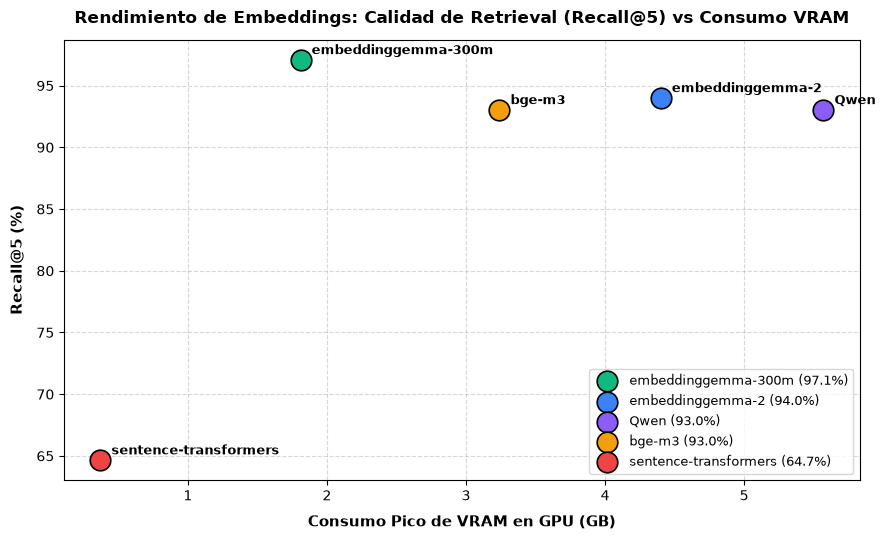

In [7]:
plt.figure(figsize=(9, 5.5), dpi=100)
colores_grafico = ["#10b981", "#3b82f6", "#8b5cf6", "#f59e0b", "#ef4444"]

for indice, fila in tabla_resultados.iterrows():
    eje_x_vram = fila["VRAM (GB)"]
    eje_y_recall5 = fila["Recall@5"] * 100
    etiqueta_modelo = fila["Modelo"]
    color_punto = colores_grafico[indice % len(colores_grafico)]
    
    plt.scatter(
        eje_x_vram, eje_y_recall5, 
        s=220, color=color_punto, edgecolors="black", linewidth=1.2, zorder=5,
        label=f"{etiqueta_modelo} ({fila['Recall@5']:.1%})"
    )
    plt.annotate(
        etiqueta_modelo, (eje_x_vram, eje_y_recall5),
        xytext=(8, 4), textcoords="offset points", fontsize=9, fontweight="bold"
    )

plt.xlabel("Consumo Pico de VRAM en GPU (GB)", fontsize=11, fontweight="bold", labelpad=8)
plt.ylabel("Recall@5 (%)", fontsize=11, fontweight="bold", labelpad=8)
plt.title("Rendimiento de Embeddings: Calidad de Retrieval (Recall@5) vs Consumo VRAM", fontsize=12, fontweight="bold", pad=12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right", frameon=True, fontsize=9)
plt.tight_layout()
plt.show()


### Paso 8: Conclusiones, Recomendación y Plan B

1. **Ganador del Escenario 1 (BOE): `google/embeddinggemma-300m`**
   - **Mayor Recall@5 (95.99%)** y mayor **MRR (0.8711)** de todos los modelos.
   - En más del 80% de los casos la respuesta exacta está en el puesto #1 (`Recall@1 = 80.29%`).
   - Su consumo de memoria es de solo **1.81 GB de VRAM**, superando a modelos que multiplican su tamaño como Qwen (2.13B, 5.57 GB VRAM).

    Para el BOE usaremos **google/embeddinggemma-300m** porque alcanza el mayor Recall@5 (95.99%) y MRR (0.8711) del benchmark, con un coste de VRAM muy bajo (1.81 GB) y alta velocidad de indexación.

2. **Plan B (con límite de 8 GB de VRAM):**
   - La elección seria la misma `google/embeddinggemma-300m` requiere apenas **1.81 GB**, dejando más de **6 GB de VRAM libres** para albergar un LLM generador local.